# Steel Plant Energy Forecasting (Track 2)

**What I'm doing:** predicting how much power the plant will use in the next 15 minutes, using only what's known right now.

**How:** I explored the data, set a simple baseline, built 43 features, tested on 5 future periods, and averaged a team of 4 models.

**Result:** RMSE **8.57**, against 12.79 for the baseline. That's 33% better.

In [1]:
!pip install -q catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.0 MB/s eta 0:00:00


## 1. Load the data

In [2]:
import pandas as pd
import numpy as np
import joblib

df = pd.read_csv("train.csv")
TARGET = "next_interval_Usage_kWh"
print(df.shape)
df.head()

(28031, 12)


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type,next_interval_Usage_kWh
0,01/01/2018 00:15,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load,4.00
1,01/01/2018 00:30,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load,3.24
2,01/01/2018 00:45,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load,3.31
3,01/01/2018 01:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load,3.82
4,01/01/2018 01:15,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load,3.28


## 2. Explore the data
What does usage look like, and does it follow a routine?

In [3]:
df["Usage_kWh"].describe()

,Usage_kWh
count,28031.000000
mean,27.923546
std,33.920138
min,2.450000
25%,3.130000
50%,4.610000
75%,51.260000
max,153.140000


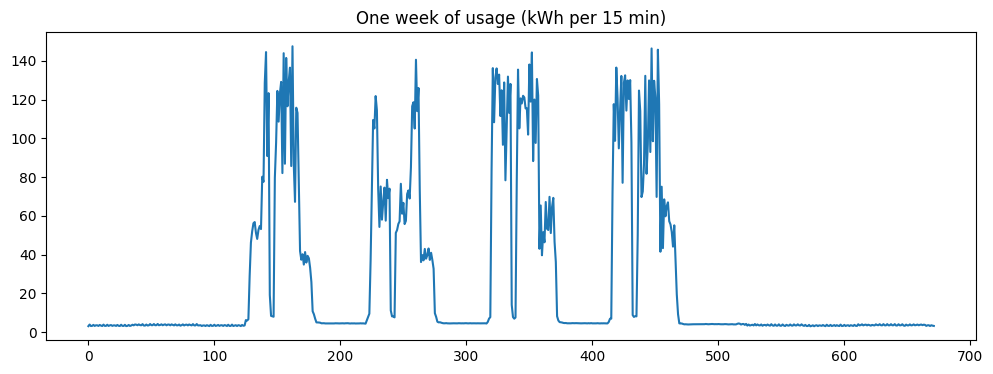

In [4]:
df["Usage_kWh"][:672].plot(figsize=(12, 4), title="One week of usage (kWh per 15 min)");

In [5]:
df.groupby("Day_of_week")["Usage_kWh"].mean().sort_values()

,Usage_kWh
Day_of_week,
Sunday,7.407210
Saturday,16.351441
Wednesday,32.083470
Friday,33.663761
Monday,34.344764
Tuesday,35.160243
Thursday,35.691344


**What we learned**
- The factory is either **idle (~3–5 kWh)** or **running (40–150 kWh)**; the median is only 4.6.
- Clear **daily routine**: machines start around 8:00, pause at lunch, stop at night.
- **Weekends are quiet**, Sunday most of all.
- **Data quirk:** each midnight reading (00:00) carries the *previous* day's date. Our code fixes this
  before building any time clue.
- So the hard part is predicting **when the machines switch on or off**.

## 3. Baseline: "next = now"
The simplest guess: the next reading equals the current one. Any real model must beat this.

In [6]:
error = df[TARGET] - df["Usage_kWh"]
print("Baseline MAE: ", np.abs(error).mean())
print("Baseline RMSE:", np.sqrt((error ** 2).mean()))

Baseline MAE:  6.527219150226535
Baseline RMSE: 14.32410787964649


## 4. The clues (features): 43 in 5 groups
A model only sees one row at a time, so we add columns describing the **recent past** and the
**time of the next reading**. Every clue uses data up to *now* only, so there's no peeking at the future.

| Group | Clues | What it tells the model |
|---|---|---|
| Raw readings (7) | usage, reactive power, CO2, power factors, NSM | What the plant is doing right now |
| Calendar & plant state (4) | day of week, weekend, load type, month | Which kind of day it is |
| Time of the next reading (5) | 15-min slot, hour, day, sin/cos of the clock | Is a shift start or lunch break coming? |
| Recent usage (18) | readings 1–12 steps ago, changes, averages and spreads over 1h/2h/4h/24h, 4h max | Is usage rising, falling, steady or jumpy? |
| Same moment on earlier days (4) | next slot yesterday and last week, busiest in 4 weeks, yesterday's jump | What usually happens at this exact time |
| Electrical (5) | apparent power (kVA), reactive power changes, power-factor change | How hard the machines are working |

**Why sin/cos of the clock?** As plain numbers, 23:45 (slot 95) and 00:00 (slot 0) look far apart.
Placing the time on a circle with sin/cos puts them next to each other, like on a real clock face.

**Why 43 clues need bigger models:** with only 9 clues, a bigger model just memorises noise (overfitting).
With 43 clues there's enough real information, so slower learning (0.03), more trees (400) and bigger
trees (63 leaves) pay off.

All of this lives in the functions below. They are **identical** to `predict.py`, so training and
prediction run the exact same pipeline.

In [7]:
TARGET = "next_interval_Usage_kWh"
MODEL_PATH = "my_model.joblib"
FEATURE_COLUMNS = ["date", "Usage_kWh", "Lagging_Current_Reactive.Power_kVarh",
                   "Leading_Current_Reactive_Power_kVarh", "CO2(tCO2)",
                   "Lagging_Current_Power_Factor", "Leading_Current_Power_Factor",
                   "NSM", "WeekStatus", "Day_of_week", "Load_Type"]
DAY = 96


def to_time(dates):
    """Parse 'dd/mm/yyyy HH:MM'. The data stamps each midnight reading with the
    previous day's date, so 00:00 readings are moved forward one day."""
    t = pd.to_datetime(dates, format="%d/%m/%Y %H:%M", errors="coerce")
    is_midnight = (t.dt.hour == 0) & (t.dt.minute == 0)
    return t + pd.to_timedelta(is_midnight.astype(int), unit="D")


def make_clues(df):
    """Add the 43 clues. Every clue uses only readings up to now (no future data)."""
    df = df.copy()
    u = df["Usage_kWh"]
    react = df["Lagging_Current_Reactive.Power_kVarh"]
    nxt = to_time(df["date"]) + pd.Timedelta(minutes=15)
    nxt_min = nxt.dt.hour * 60 + nxt.dt.minute


    df["dow"] = df["Day_of_week"].map({"Monday": 0, "Tuesday": 1, "Wednesday": 2, "Thursday": 3,
                                       "Friday": 4, "Saturday": 5, "Sunday": 6})
    df["is_weekend"] = (df["WeekStatus"] == "Weekend").astype(int)
    df["load_type"] = df["Load_Type"].map({"Light_Load": 0, "Medium_Load": 1, "Maximum_Load": 2})
    df["month"] = to_time(df["date"]).dt.month


    df["next_slot"] = nxt_min // 15
    df["next_hour"] = nxt.dt.hour
    df["next_dow"] = nxt.dt.dayofweek
    df["next_hour_sin"] = np.sin(2 * np.pi * nxt_min / 1440)
    df["next_hour_cos"] = np.cos(2 * np.pi * nxt_min / 1440)

    for k in [1, 2, 3, 4, 8, 12]:
        df[f"usage_lag{k}"] = u.shift(k)
    df["usage_diff1"] = u - u.shift(1)
    df["usage_diff4"] = u - u.shift(4)
    for w in [4, 8, 16, 96]:
        r = u.rolling(w, min_periods=1)
        df[f"usage_rmean{w}"] = r.mean()
        df[f"usage_rstd{w}"] = r.std()
    df["usage_rmax16"] = u.rolling(16, min_periods=1).max()
    df["usage_ewm4"] = u.ewm(span=4, adjust=False).mean()

    df["usage_sameslot_1d"] = u.shift(DAY - 1)
    df["usage_sameslot_7d"] = u.shift(7 * DAY - 1)
    df["sameslot_4w_max"] = pd.concat([u.shift(7 * DAY * k - 1) for k in range(1, 5)],
                                      axis=1).max(axis=1)
    df["yday_jump"] = u.shift(DAY - 1) - u.shift(DAY)

    df["lagkvarh_lag1"] = react.shift(1)
    df["lagkvarh_diff1"] = react - react.shift(1)
    df["apparent_kva"] = np.sqrt(u ** 2 + react ** 2)
    df["pf_lag_diff1"] = df["Lagging_Current_Power_Factor"].diff()
    df["load_type_lag1"] = df["load_type"].shift(1)
    return df


CLUES = [

    "Usage_kWh", "Lagging_Current_Reactive.Power_kVarh", "Leading_Current_Reactive_Power_kVarh",
    "CO2(tCO2)", "Lagging_Current_Power_Factor", "Leading_Current_Power_Factor", "NSM",
    "dow", "is_weekend", "load_type", "month",
    "next_slot", "next_hour", "next_dow", "next_hour_sin", "next_hour_cos",
    "usage_lag1", "usage_lag2", "usage_lag3", "usage_lag4", "usage_lag8", "usage_lag12",
    "usage_diff1", "usage_diff4",
    "usage_rmean4", "usage_rstd4", "usage_rmean8", "usage_rstd8",
    "usage_rmean16", "usage_rstd16", "usage_rmean96", "usage_rstd96",
    "usage_rmax16", "usage_ewm4",
    "usage_sameslot_1d", "usage_sameslot_7d", "sameslot_4w_max", "yday_jump",
    "lagkvarh_lag1", "lagkvarh_diff1", "apparent_kva", "pf_lag_diff1", "load_type_lag1",
]


def make_team():
    """The 4 models. Each learns differently; their average makes fewer big mistakes."""
    import catboost as cb
    import lightgbm as lgb
    import xgboost as xgb
    shared = dict(learning_rate=0.03, num_leaves=63, min_child_samples=30, feature_fraction=0.8,
                  bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0, n_estimators=400, verbose=-1)
    return [
        lgb.LGBMRegressor(**shared, objective="regression", random_state=1),
        lgb.LGBMRegressor(**shared, objective="huber", alpha=10, random_state=2),
        xgb.XGBRegressor(n_estimators=600, learning_rate=0.03, max_depth=7, subsample=0.8,
                         colsample_bytree=0.8, min_child_weight=5, random_state=3),
        cb.CatBoostRegressor(iterations=1500, learning_rate=0.05, depth=8, verbose=0,
                             random_seed=4, allow_writing_files=False),
    ]


def follows_on(history, new_df):
    """True if new_df starts exactly 15 minutes after history ends."""
    try:
        gap = to_time(new_df["date"].iloc[:1]).iloc[0] - to_time(history["date"].iloc[-1:]).iloc[0]
        return gap == pd.Timedelta(minutes=15)
    except Exception:
        return False


def predict(new_df, history=None, model_path=MODEL_PATH):
    """Predict next-interval kWh for every row of new_df (a DataFrame).
    history: earlier readings to put in front; by default the stored end of train.csv,
    used only when new_df follows on from it in time."""
    saved = joblib.load(model_path)
    new_df = new_df.drop(columns=[TARGET], errors="ignore").reset_index(drop=True)

    if history is None:
        history = saved.get("history")
    n_hist = 0
    if history is not None and follows_on(history, new_df):
        history = history.drop(columns=[TARGET], errors="ignore").tail(7 * DAY)
        n_hist = len(history)
        new_df = pd.concat([history, new_df], ignore_index=True)

    data = make_clues(new_df)
    guesses = [m.predict(data[saved["clues"]]) for m in saved["models"]]
    pred = np.clip(np.mean(guesses, axis=0), 0, None)
    return pred[n_hist:]

In [8]:
data = make_clues(df).dropna(subset=["usage_lag1"])
print(len(CLUES), "clues")
data[CLUES].head(3)

43 clues


,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,dow,is_weekend,load_type,...,usage_ewm4,usage_sameslot_1d,usage_sameslot_7d,sameslot_4w_max,yday_jump,lagkvarh_lag1,lagkvarh_diff1,apparent_kva,pf_lag_diff1,load_type_lag1
1,4.00,4.46,0.0,0.0,66.77,100.0,1800,0,0,0,...,3.50200,NaN,NaN,NaN,NaN,2.95,1.51,5.990960,-6.44,0.0
2,3.24,3.28,0.0,0.0,70.28,100.0,2700,0,0,0,...,3.39720,NaN,NaN,NaN,NaN,4.46,-1.18,4.610423,3.51,0.0
3,3.31,3.56,0.0,0.0,68.09,100.0,3600,0,0,0,...,3.36232,NaN,NaN,NaN,NaN,3.28,0.28,4.861039,-2.19,0.0


## 5. How we got here (experiment log)
Clues and models were changed **one step at a time** and kept only if the 5-period RMSE (section 6) improved.

| Step | Change | RMSE | Kept? |
|---|---|---|---|
| 1 | Baseline: next = now | 12.79 | (reference) |
| 2 | LightGBM, 5 clues (usage, lag1, 1h average, hour, weekend) | 9.64 | ✓ |
| 3 | + load type, + slot of next reading | 8.99 | ✓ |
| 4 | + change since last reading (alone) | 9.02 | ✗ worse |
| 5 | + 24-hour average, + 4-hour maximum (9 clues) | 8.90 | ✓ |
| 6 | Team of 3 models on 9 clues | 8.86 | ✓ |
| 7 | Adding single extra clues to the 9 (CO2, lag2, yesterday's jump…) | 8.95–9.13 | ✗ all worse |
| 8 | **43 clues + bigger models + team of 4** | **8.57** | ✓ final |

Lesson: one clue at a time can mislead. Small additions to 9 clues all hurt, but the full set of 43
clues *together with* bigger models won. Testing on several periods is what tells them apart.

## 6. Fair testing: 5 future exams (TimeSeriesSplit)
We never shuffle time. Each round trains on the **past** and tests on the **next 4 weeks**
(2,688 rows), five times, then averages. Every model and the baseline are scored on the same periods.

*(Takes about 4 minutes: CatBoost is slow.)*

In [9]:
from sklearn.model_selection import TimeSeriesSplit

names = ["LightGBM (squared error)", "LightGBM (Huber)", "XGBoost", "CatBoost"]
scores = {n: [] for n in names + ["Team of 4", "Baseline"]}
all_actual, all_team = [], []

for train_rows, test_rows in TimeSeriesSplit(n_splits=5, test_size=2688).split(data):
    train, test = data.iloc[train_rows], data.iloc[test_rows]
    y = test[TARGET].values
    guesses = [m.fit(train[CLUES], train[TARGET]).predict(test[CLUES]) for m in make_team()]
    team = np.mean(guesses, axis=0)
    for n, g in zip(names + ["Team of 4", "Baseline"], guesses + [team, test["Usage_kWh"].values]):
        scores[n].append(np.sqrt(((y - g) ** 2).mean()))
    all_actual.extend(y); all_team.extend(team)

table = pd.DataFrame({"RMSE": {n: np.mean(s) for n, s in scores.items()},
                      "spread": {n: np.std(s) for n, s in scores.items()}}).sort_values("RMSE")
print("Team RMSE per exam:", np.round(scores["Team of 4"], 2))
table.round(2)

Team RMSE per exam: [9.1  8.47 8.87 7.93 8.45]


,RMSE,spread
Team of 4,8.57,0.40
CatBoost,8.64,0.42
XGBoost,8.65,0.38
LightGBM (squared error),8.71,0.41
LightGBM (Huber),8.79,0.43
Baseline,12.79,0.72


**Why a team?** Different models make different mistakes. Huber-loss LightGBM is less pulled by
spikes, CatBoost and XGBoost build their trees differently. Averaging cancels some of the mistakes, so
the team beats every single model.

## 7. "Accuracy" for a number forecast
Accuracy (right/wrong) is for yes/no questions. For a number we measure **how close** the guesses
are, using the 5-exam predictions the models never trained on.

In [10]:
from sklearn.metrics import r2_score

actual, pred = np.array(all_actual), np.array(all_team)
miss = np.abs(actual - pred)
print("RMSE:", round(np.sqrt((miss ** 2).mean()), 2), "| MAE:", round(miss.mean(), 2))
print("R² (share of ups and downs explained):", round(r2_score(actual, pred), 3))
for k in [2, 5, 10]:
    print(f"Guesses within {k} kWh: {np.mean(miss < k):.1%}")
print(f"Running/idle state (20 kWh cut) correct: {np.mean((pred > 20) == (actual > 20)):.1%}")

RMSE: 8.57 | MAE: 4.06
R² (share of ups and downs explained): 0.923
Guesses within 2 kWh: 65.9%
Guesses within 5 kWh: 75.9%
Guesses within 10 kWh: 86.2%
Running/idle state (20 kWh cut) correct: 98.7%


## 8. Why RMSE can't go much lower

In [11]:
baseline_guess = data["Usage_kWh"].values[-len(actual):]
jump = np.abs(actual - baseline_guess) > 20
print(f"Big jumps are {jump.mean():.0%} of intervals but cause "
      f"{(miss[jump] ** 2).sum() / (miss ** 2).sum():.0%} of the squared error")

Big jumps are 10% of intervals but cause 64% of the squared error


At 7:45 nothing in the data says a worker will press "start" at 8:00. Sudden starts and stops are
the main remaining error; beating that would need new information, such as the production schedule.

## 9. Train the final team on ALL the data and save it
We also store the last 7 days of train.csv. The test file continues right after it, so its first
rows can use this as their "past" for lags and same-time-yesterday clues.

In [13]:
final_team = [m.fit(data[CLUES], data[TARGET]) for m in make_team()]
history = df[FEATURE_COLUMNS].tail(7 * DAY)
joblib.dump({"models": final_team, "clues": CLUES, "history": history}, MODEL_PATH)

['my_model.joblib']

## 10. Predict new data, like the organisers will
`predict()` (defined in section 4) is what the organisers call: it takes the 11 feature columns
(no target), adds the history if the dates follow on, builds the 43 clues, asks all 4 models and averages.

We pretend the last 500 rows are a new test file. (These rows were also used in training, so this
checks the code **runs correctly**; the honest score is the 5-exam result above.)

In [14]:
past = df.iloc[:-500]
fake_test = df[FEATURE_COLUMNS].tail(500)
preds = predict(fake_test, history=past[FEATURE_COLUMNS])

check = pd.DataFrame({"date": fake_test["date"], "predicted_kWh": preds,
                      "actual_kWh": df[TARGET].tail(500).values})
check[["date", "predicted_kWh"]].to_csv("predictions.csv", index=False)
check.head()

,date,predicted_kWh,actual_kWh
27531,14/10/2018 19:00,3.005476,2.99
27532,14/10/2018 19:15,3.034506,2.99
27533,14/10/2018 19:30,3.036247,2.95
27534,14/10/2018 19:45,3.034863,2.99
27535,14/10/2018 20:00,3.066384,3.06


## Summary
- **Final model:** average of 4 tree models (LightGBM ×2, XGBoost, CatBoost) on 43 clues in 5 groups.
- **Honest score (5 future periods):** RMSE ≈ 8.57 vs 12.79 for the baseline, about 33% better.
- **Biggest lesson:** the hard part is sudden machine starts; the 8:00 start and post-lunch restart cause most errors.
- **Practical use:** a plant manager can see a high-usage interval coming and shift secondary equipment to avoid penalty charges.